In [1]:
import json
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo = Path("/content/risk-calibrated-early-stopping")
revision = "896a9e2"

if not (repo / ".git").is_dir():
    subprocess.run(
        ["git", "clone", "https://github.com/nnamanx/risk-calibrated-early-stopping.git", str(repo)],
        check=True,
    )

results_path = "experiments/week2-t4-pilots/results"

def read_saved_file(path):
    return subprocess.check_output(
        ["git", "-C", str(repo), "show", f"{revision}:{path}"],
        text=True,
    )

frames = []
summaries = []

for number in range(1, 13):
    run_id = f"pilot-{number:02d}"
    run_path = f"{results_path}/{run_id}"
    rows = read_saved_file(f"{run_path}/metrics.jsonl").splitlines()
    log = pd.DataFrame(json.loads(row) for row in rows)
    summary = json.loads(read_saved_file(f"{run_path}/summary_2048.json"))

    assert log["step"].tolist() == list(range(2049)), f"{run_id}: missing or duplicate steps"
    assert log.loc[log["monitor_loss"].notna(), "step"].tolist() == list(range(0, 2049, 128))
    assert summary["last_step"] == 2048 and summary["status"] == "completed", run_id

    frames.append(log.assign(run_id=run_id))
    summaries.append({**summary, "run_id": run_id})

logs = pd.concat(frames, ignore_index=True)
runs = pd.DataFrame(summaries).set_index("run_id")
print(f"Verified {len(runs)} completed runs and {len(logs):,} metric rows.")

Verified 12 completed runs and 24,588 metric rows.


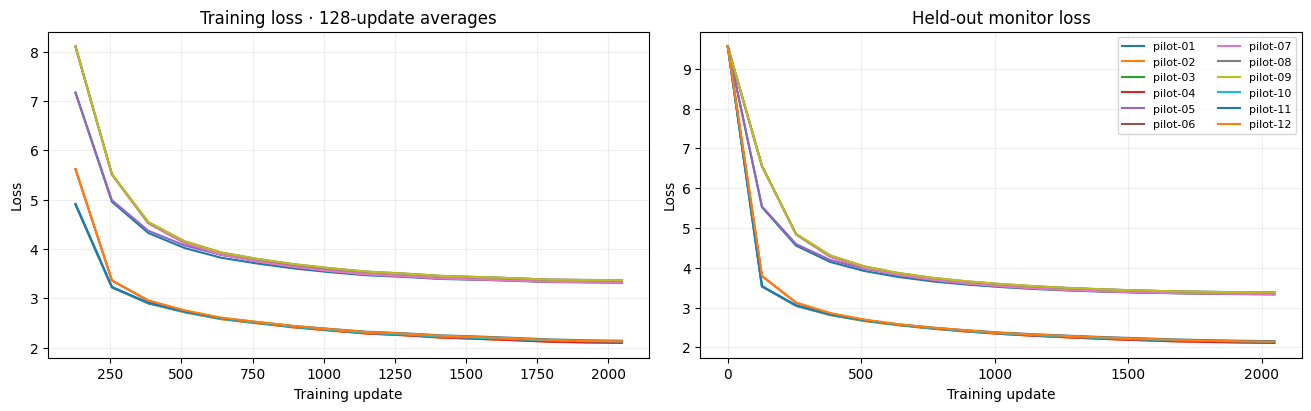

,nonfinite_train_loss,nonfinite_gradient_norm,training_block_increases,monitor_loss_increases
run_id,,,,
pilot-01,0,0,0,0
pilot-02,0,0,0,0
pilot-03,0,0,0,0
pilot-04,0,0,0,0
pilot-05,0,0,0,0
pilot-06,0,0,0,0
pilot-07,0,0,0,0
pilot-08,0,0,0,0
pilot-09,0,0,0,0


In [2]:
train = logs.loc[logs["step"] > 0].copy()
train["block_end"] = ((train["step"] - 1) // 128 + 1) * 128
monitor = logs.dropna(subset=["monitor_loss"]).copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
checks = []

for run_id, training in train.groupby("run_id"):
    block_loss = training.groupby("block_end")["train_loss"].mean()
    held_out = monitor[monitor["run_id"] == run_id]

    axes[0].plot(block_loss.index, block_loss, label=run_id)
    axes[1].plot(held_out["step"], held_out["monitor_loss"], label=run_id)

    checks.append({
        "run_id": run_id,
        "nonfinite_train_loss": int((~np.isfinite(training["train_loss"])).sum()),
        "nonfinite_gradient_norm": int((~np.isfinite(training["gradient_norm"])).sum()),
        "training_block_increases": int((block_loss.diff() > 0).sum()),
        "monitor_loss_increases": int((held_out["monitor_loss"].diff() > 0).sum()),
    })

for ax, title in zip(axes, ["Training loss · 128-update averages", "Held-out monitor loss"]):
    ax.set(title=title, xlabel="Training update", ylabel="Loss")
    ax.grid(alpha=0.2)

axes[1].legend(ncol=2, fontsize=8)
plt.show()
display(pd.DataFrame(checks).set_index("run_id"))

monitor loss          rank among 12         
run_id     pilot-02 pilot-04      pilot-02 pilot-04
step                                               
128         3.52739  3.79107             1        5
512         2.65790  2.68649             1        5
1152        2.28725  2.28820             1        2
1280        2.24839  2.24838             2        1
1408        2.21323  2.21127             2        1
2048        2.11727  2.11126             2        1

First observed checkpoint where Pilot 04 leads Pilot 02: 1280
Final loss gap: 0.00602


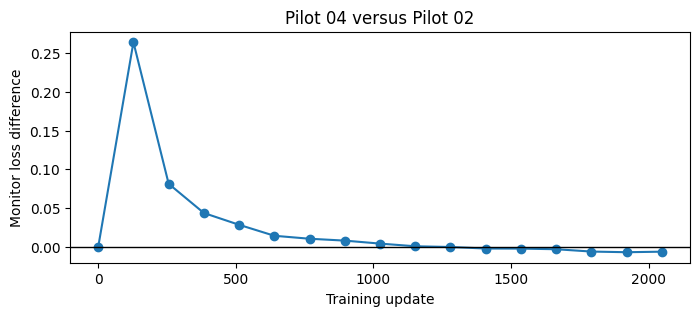

In [3]:
loss_by_step = monitor.pivot(index="step", columns="run_id", values="monitor_loss")
ranks = loss_by_step.rank(axis=1, method="min").astype(int)

pair = ["pilot-02", "pilot-04"]
steps = [128, 512, 1152, 1280, 1408, 2048]

display(pd.concat({
    "monitor loss": loss_by_step.loc[steps, pair].round(5),
    "rank among 12": ranks.loc[steps, pair],
}, axis=1))

gap = loss_by_step["pilot-04"] - loss_by_step["pilot-02"]
first_ahead = gap[gap < 0].index.min()
print(f"First observed checkpoint where Pilot 04 leads Pilot 02: {first_ahead}")
print(f"Final loss gap: {abs(gap.loc[2048]):.5f}")

ax = gap.plot(marker="o", figsize=(8, 3))
ax.axhline(0, color="black", linewidth=1)
ax.set(
    title="Pilot 04 versus Pilot 02",
    xlabel="Training update",
    ylabel="Monitor loss difference",
)
plt.show()

In [4]:
time_columns = [
    "train_seconds",
    "monitor_seconds",
    "checkpoint_seconds_this_session",
    "session_wall_seconds",
]

per_run_minutes = runs[time_columns] / 60
display(per_run_minutes.round(2))
display(per_run_minutes.sum().rename("total_minutes").round(2))

evaluation_share = runs["monitor_seconds"].sum() / runs["session_wall_seconds"].sum()
print(f"Monitor evaluation share of wall time: {evaluation_share:.2%}")
print(f"Total training tokens: {int(runs['tokens_seen'].sum()):,}")

cumulative = (
    logs.loc[logs["step"].isin([128, 512, 1024, 2048])]
    .groupby("step")
    .agg(
        training_tokens=("tokens_seen", "sum"),
        training_seconds=("train_seconds", "sum"),
        evaluation_seconds=("monitor_seconds", "sum"),
    )
)

cumulative["training_plus_evaluation_min"] = (
    cumulative["training_seconds"] + cumulative["evaluation_seconds"]
) / 60

display(cumulative[["training_tokens", "training_plus_evaluation_min"]].round(2))

,train_seconds,monitor_seconds,checkpoint_seconds_this_session,session_wall_seconds
run_id,,,,
pilot-01,7.91,0.38,0.03,8.64
pilot-02,7.92,0.41,0.03,8.67
pilot-03,8.01,0.39,0.03,8.73
pilot-04,7.88,0.41,0.03,8.63
pilot-05,7.98,0.39,0.03,8.70
pilot-06,7.95,0.39,0.03,8.68
pilot-07,7.90,0.39,0.03,8.66
pilot-08,7.98,0.39,0.03,8.68
pilot-09,8.07,0.39,0.03,8.80


,total_minutes
train_seconds,95.54
monitor_seconds,4.71
checkpoint_seconds_this_session,0.35
session_wall_seconds,104.30


Monitor evaluation share of wall time: 4.52%
Total training tokens: 402,653,184


,training_tokens,training_plus_evaluation_min
step,,
128,25165824,7.94
512,100663296,26.40
1024,201326592,50.99
2048,402653184,100.25


In [5]:
pilot_01 = runs.loc["pilot-01"]
assert runs["restored_from_step"].eq(0).all()

restart_comparison = pd.DataFrame([
    {
        "run": "Uninterrupted Pilot 01",
        "resumed_from_step": 0,
        "final_monitor_loss_displayed": f"{pilot_01['final_monitor_loss']:.4f}",
        "total_wall_minutes": round(pilot_01["session_wall_seconds"] / 60, 2),
        "restore_seconds": np.nan,
        "source": "Archived GitHub summary",
    },
    {
        "run": "Paused and resumed Pilot 01",
        "resumed_from_step": 512,
        "final_monitor_loss_displayed": "3.3310",
        "total_wall_minutes": 10.05,
        "restore_seconds": 0.21,
        "source": "Earlier Colab output",
    },
]).set_index("run")

display(restart_comparison.fillna("—"))

,resumed_from_step,final_monitor_loss_displayed,total_wall_minutes,restore_seconds,source
run,,,,,
Uninterrupted Pilot 01,0,3.3310,8.64,—,Archived GitHub summary
Paused and resumed Pilot 01,512,3.3310,10.05,0.21,Earlier Colab output
